In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

river_df = pd.read_csv("RiverWaterQualityOverYears (1).csv")

print("Dataset Shape:", river_df.shape)

print("\nColumn Names:")
print(river_df.columns.tolist())

print("\nFirst 5 Records:")
display(river_df.head())

print("\nData Types:")
print(river_df.dtypes)

print("\nMissing Values:")
print(river_df.isnull().sum())

print("\nDuplicate Records:", river_df.duplicated().sum())

Dataset Shape: (10006, 22)

Column Names:
['Station Code', 'Monitoring Location', 'State', 'Temperature (°C) Min', 'Temperature (°C) Max', 'Dissolved Oxygen (mg/L) Min', 'Dissolved Oxygen (mg/L) Max', 'pH Min', 'pH Max', 'Conductivity (µmho/cm) Min', 'Conductivity (µmho/cm) Max', '  BOD (mg/L) Min', ' BOD (mg/L) Max', 'Nitrate N (mg/L) Min', 'Nitrate N (mg/L) Max', 'Fecal Coliform (MPN/100ml) Min', 'Fecal Coliform (MPN/100ml) Max', ' Total Coliform (MPN/100ml) Min', ' Total Coliform (MPN/100ml) Max', ' Fecal Streptococci (MPN/100ml) Min', ' Fecal Streptococci (MPN/100ml) Max', 'Year']

First 5 Records:


,Station Code,Monitoring Location,State,Temperature (°C) Min,Temperature (°C) Max,Dissolved Oxygen (mg/L) Min,Dissolved Oxygen (mg/L) Max,pH Min,pH Max,Conductivity (µmho/cm) Min,...,BOD (mg/L) Max,Nitrate N (mg/L) Min,Nitrate N (mg/L) Max,Fecal Coliform (MPN/100ml) Min,Fecal Coliform (MPN/100ml) Max,Total Coliform (MPN/100ml) Min,Total Coliform (MPN/100ml) Max,Fecal Streptococci (MPN/100ml) Min,Fecal Streptococci (MPN/100ml) Max,Year
0,1001,RIVER BEAS AT U/S MANALI,HIMACHAL PRADESH,2,24,7.8,9.2,7.2,8.2,68,...,2.8,0.32,1.15,2,170,63,540,2,2,2023
1,2601,RIVER BEAS AT D/S MANALI,HIMACHAL PRADESH,2,13,7.6,9,6.5,8.1,58,...,2.8,0.32,1.87,110,1600,920,1600,2,2,2023
2,4444,RIVER BEAS D/S OF WASTE PROCESSING FACILITY AT...,HIMACHAL PRADESH,2,13,7.8,8.8,6.7,7.8,62,...,2.8,0.32,1.08,110,1600,350,1600,2,2,2023
3,4037,RIVER BEAS D/S MANALSU NALLAH,HIMACHAL PRADESH,2,14,7.9,8.9,6.3,8,52,...,1,0.32,1.74,22,110,79,540,2,2,2023
4,3866,RIVER BEAS U/S BEFORE CONF. OF MANALSU NALLAH,HIMACHAL PRADESH,2,13,7.8,9.1,7,7.8,51,...,1,0.32,0.97,23,120,110,430,2,2,2023



Data Types:
Station Code                             str
Monitoring Location                      str
State                                    str
Temperature (°C) Min                     str
Temperature (°C) Max                     str
Dissolved Oxygen (mg/L) Min              str
Dissolved Oxygen (mg/L) Max              str
pH Min                                   str
pH Max                                   str
Conductivity (µmho/cm) Min               str
Conductivity (µmho/cm) Max               str
  BOD (mg/L) Min                         str
 BOD (mg/L) Max                          str
Nitrate N (mg/L) Min                     str
Nitrate N (mg/L) Max                     str
Fecal Coliform (MPN/100ml) Min           str
Fecal Coliform (MPN/100ml) Max           str
 Total Coliform (MPN/100ml) Min          str
 Total Coliform (MPN/100ml) Max          str
 Fecal Streptococci (MPN/100ml) Min      str
 Fecal Streptococci (MPN/100ml) Max      str
Year                                   int

In [2]:
river_work = river_df.copy()

river_work.columns = river_work.columns.str.strip()

metadata_cols = [
    "Station Code",
    "Monitoring Location",
    "State",
    "Year"
]

measurement_cols = [
    col for col in river_work.columns
    if col not in metadata_cols
]

print("Measurement columns:", len(measurement_cols))

for col in measurement_cols:
    values = river_work[col].astype("string").str.strip()

    numeric_values = pd.to_numeric(
        values, errors="coerce"
    )

    invalid = values[
        values.notna() &
        values.ne("") &
        numeric_values.isna()
    ]

    if len(invalid) > 0:
        print("\n", col)
        print(invalid.value_counts().head(10))

Measurement columns: 18

 Temperature (°C) Min
Temperature (°C) Min
-    167
_      5
Name: count, dtype: Int64

 Temperature (°C) Max
Temperature (°C) Max
-    167
_      5
Name: count, dtype: Int64

 Dissolved Oxygen (mg/L) Min
Dissolved Oxygen (mg/L) Min
-      23
BDL    13
_       3
nil     1
Name: count, dtype: Int64

 Dissolved Oxygen (mg/L) Max
Dissolved Oxygen (mg/L) Max
-      23
BDL     4
_       3
Name: count, dtype: Int64

 pH Min
pH Min
-    14
Name: count, dtype: Int64

 pH Max
pH Max
-    14
Name: count, dtype: Int64

 Conductivity (µmho/cm) Min
Conductivity (µmho/cm) Min
-    175
_      9
Name: count, dtype: Int64

 Conductivity (µmho/cm) Max
Conductivity (µmho/cm) Max
-           175
_             9
76-\n 00      1
1-\n 586      1
1-\n 670      1
Name: count, dtype: Int64

 BOD (mg/L) Min
BOD (mg/L) Min
BDL    913
-       19
Name: count, dtype: Int64

 BOD (mg/L) Max
BOD (mg/L) Max
BDL    206
-       19
Name: count, dtype: Int64

 Nitrate N (mg/L) Min
Nitrate N (mg/L) 

In [3]:
known_markers = ["-", "_", "--", "nil", "BDL"]

for col in measurement_cols:

    values = river_work[col].astype("string").str.strip()

    numeric_values = pd.to_numeric(
        values, errors="coerce"
    )

    invalid = values[
        values.notna() &
        values.ne("") &
        numeric_values.isna() &
        ~values.isin(known_markers)
    ]

    if len(invalid) > 0:
        print("\nColumn:", col)
        print(invalid.value_counts().to_string())


Column: Conductivity (µmho/cm) Max
Conductivity (µmho/cm) Max
76-\n 00    1
1-\n 586    1
1-\n 670    1

Column: Nitrate N (mg/L) Min
Nitrate N (mg/L) Min
0..    1

Column: Nitrate N (mg/L) Max
Nitrate N (mg/L) Max
.1.4     1
.2.00    1

Column: Fecal Coliform (MPN/100ml) Max
Fecal Coliform (MPN/100ml) Max
49000\n 0     2
13000\n 00    1
23000\n 00    1
23000\n 0     1
21000\n 0     1

Column: Total Coliform (MPN/100ml) Min
Total Coliform (MPN/100ml) Min
17000\n 0    1
11000\n 0    1

Column: Total Coliform (MPN/100ml) Max
Total Coliform (MPN/100ml) Max
16000\n 0      5
11000\n 00     2
160000\n 0     2
21000\n 00     1
58000\n 00     1
49000\n 0      1
63000\n 0      1
3300000\n 0    1

Column: Fecal Streptococci (MPN/100ml) Max
Fecal Streptococci (MPN/100ml) Max
5400000\n 0    4
7800000\n 0    4
46 0000        1


In [4]:
known_markers = ["-", "_", "--", "nil", "BDL"]

for col in measurement_cols:

    values = river_work[col].astype("string").str.strip()

    numeric_values = pd.to_numeric(
        values, errors="coerce"
    )

    invalid = values[
        values.notna() &
        values.ne("") &
        numeric_values.isna() &
        ~values.isin(known_markers)
    ]

    if len(invalid) > 0:
        print("\nCOLUMN:", col)

        display(
            river_work.loc[
                invalid.index,
                metadata_cols + [col]
            ]
        )


COLUMN: Conductivity (µmho/cm) Max


,Station Code,Monitoring Location,State,Year,Conductivity (µmho/cm) Max
1932,1125,"RIVER YAMUNA AT AGRA U/S, U.P.(KAILASH GHAT)",UTTAR PRADESH,2022,76-\n 00
1933,1126,"RIVER YAMUNA AT D/S\n OF AGRA, U.P.",UTTAR PRADESH,2022,1-\n 586
1934,1498,"RIVER YAMUNA AT BATESWAR, U.P",UTTAR PRADESH,2022,1-\n 670



COLUMN: Nitrate N (mg/L) Min


,Station Code,Monitoring Location,State,Year,Nitrate N (mg/L) Min
3368,1815,RIVER GANGA AT\n MOKAMA (D/S),BIHAR,2021,0..



COLUMN: Nitrate N (mg/L) Max


,Station Code,Monitoring Location,State,Year,Nitrate N (mg/L) Max
5081,2682,NIRA RIVER AT U/S OF JUBILANT ORGANOSIS (DATTA...,MAHARASHTRA,2018,.1.4
7317,1265,"KHAROON AT RAIPUR U/S, CHHATTISGARH",CHHATTISGARH,2013,.2.00


... (4 outputs left out)


COLUMN: Total Coliform (MPN/100ml) Max


,Station Code,Monitoring Location,State,Year,Total Coliform (MPN/100ml) Max
1670,30009,RIVER SUTLEJ AT NANGAL (H.P.),HIMACHAL PRADESH,2022,16000\n 0
1686,10028,RIVER SUTLEJ AT LUDHIANA D/S,PUNJAB,2022,21000\n 00
1692,1020,"RIVER SUTLEJ AT 100M D/S BUDHA NALA CONFL., LU...",PUNJAB,2022,58000\n 00
1694,10025,RIVER SUTLEJ AT JALANDHAR U/S (PEERU SHAH KA D...,PUNJAB,2022,49000\n 0
1695,10026,RIVER SUTLEJ AT JALANDHAR D/S\n (MALSIAN BRIDGE),PUNJAB,2022,63000\n 0
1696,1021,RIVER SUTLEJ AT BOAT BDG. DHARMKOTNAKODAR\n RO...,PUNJAB,2022,11000\n 00
1697,1381,"RIVER SUTLEJ AT D/S EAST BEIN, PUNJAB",PUNJAB,2022,11000\n 00
3313,30005,RIVER GANGA AT SULTANPUR\n (UTTARAKHAND),UTTARAKHAND,2021,160000\n 0
3314,30006,RIVER GANGA AT BIJNOR\n (U.P.),UTTAR PRADESH,2021,160000\n 0
3682,30064,RIVER CHURNI AT BIJOYPUR\n (WEST BENGAL),WEST\n BENGAL,2021,3300000\n 0



COLUMN: Fecal Streptococci (MPN/100ml) Max


,Station Code,Monitoring Location,State,Year,Fecal Streptococci (MPN/100ml) Max
3423,1121,"RIVER YAMUNA AT\n NIZAMUDDIN, DELHI",DELHI,2021,46 0000
7922,1812,YAMUNA AT OKHLA AFTER MEETING OF SHAHDARA DRAI...,DELHI,2020,5400000\n 0
8017,1478,"KALINADI AT D/S OF MUZAFFAR NAGAR, U.P.",UTTAR PRADESH,2020,7800000\n 0
8131,1812,YAMUNA AT OKHLA AFTER MEETING OF SHAHDARA DRAI...,DELHI,2020,5400000\n 0
8180,1478,"KALINADI AT D/S OF MUZAFFAR NAGAR, U.P.",UTTAR PRADESH,2020,7800000\n 0
9094,1812,YAMUNA AT OKHLA AFTER MEETING OF SHAHDARA DRAI...,DELHI,2019,5400000\n 0
9189,1478,"KALINADI AT D/S OF MUZAFFAR NAGAR, U.P.",UTTAR PRADESH,2019,7800000\n 0
9303,1812,YAMUNA AT OKHLA AFTER MEETING OF SHAHDARA DRAI...,DELHI,2019,5400000\n 0
9352,1478,"KALINADI AT D/S OF MUZAFFAR NAGAR, U.P.",UTTAR PRADESH,2019,7800000\n 0


In [5]:
river_numeric = river_work.copy()

bdl_flags = pd.DataFrame(index=river_work.index)

missing_markers = ["-", "_", "--", "nil"]

for col in measurement_cols:

    values = river_work[col].astype("string").str.strip()

    bdl_flags[col + "_BDL"] = values.eq("BDL").fillna(False)

    values = values.replace(
        missing_markers + ["BDL", ""],
        pd.NA
    )

    river_numeric[col] = pd.to_numeric(
        values,
        errors="coerce"
    )

print("Numeric conversion completed.")

print("\nMeasurement data types:")
print(river_numeric[measurement_cols].dtypes)

print("\nMissing values after conversion:")
print(river_numeric[measurement_cols].isnull().sum())

print("\nTotal BDL entries:")
print(bdl_flags.sum().sum())

Numeric conversion completed.

Measurement data types:
Temperature (°C) Min                  Float64
Temperature (°C) Max                  Float64
Dissolved Oxygen (mg/L) Min           Float64
Dissolved Oxygen (mg/L) Max           Float64
pH Min                                Float64
pH Max                                Float64
Conductivity (µmho/cm) Min            Float64
Conductivity (µmho/cm) Max            Float64
BOD (mg/L) Min                        Float64
BOD (mg/L) Max                        Float64
Nitrate N (mg/L) Min                  Float64
Nitrate N (mg/L) Max                  Float64
Fecal Coliform (MPN/100ml) Min        Float64
Fecal Coliform (MPN/100ml) Max        Float64
Total Coliform (MPN/100ml) Min        Float64
Total Coliform (MPN/100ml) Max        Float64
Fecal Streptococci (MPN/100ml) Min    Float64
Fecal Streptococci (MPN/100ml) Max    Float64
dtype: object

Missing values after conversion:
Temperature (°C) Min                   302
Temperature (°C) Max      

In [6]:
missing_summary = pd.DataFrame({
    "Missing Count": river_numeric[measurement_cols].isnull().sum(),
    "Missing Percentage": (
        river_numeric[measurement_cols].isnull().mean() * 100
    ).round(2),
    "BDL Count": bdl_flags.sum()
})

missing_summary["Available Values"] = (
    len(river_numeric) - missing_summary["Missing Count"]
)

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

print("MISSING VALUE AND BDL SUMMARY")
display(missing_summary)

print("\nTotal rows:", len(river_numeric))
print("Total measurement cells:", len(river_numeric) * len(measurement_cols))
print("Total missing measurement cells:",
      river_numeric[measurement_cols].isnull().sum().sum())
print("Total BDL entries:", bdl_flags.sum().sum())

MISSING VALUE AND BDL SUMMARY


,Missing Count,Missing Percentage,BDL Count,Available Values
Fecal Streptococci (MPN/100ml) Max,6864.0,68.60,<NA>,3142.0
Fecal Streptococci (MPN/100ml) Min,6856.0,68.52,<NA>,3150.0
Nitrate N (mg/L) Min,2846.0,28.44,<NA>,7160.0
Fecal Coliform (MPN/100ml) Max,1379.0,13.78,<NA>,8627.0
Fecal Coliform (MPN/100ml) Min,1374.0,13.73,<NA>,8632.0
Nitrate N (mg/L) Max,1208.0,12.07,<NA>,8798.0
Total Coliform (MPN/100ml) Max,1202.0,12.01,<NA>,8804.0
Total Coliform (MPN/100ml) Min,1192.0,11.91,<NA>,8814.0
BOD (mg/L) Min,1062.0,10.61,<NA>,8944.0
Conductivity (µmho/cm) Max,422.0,4.22,<NA>,9584.0



Total rows: 10006
Total measurement cells: 180108
Total missing measurement cells: 26164
Total BDL entries: 3967


In [7]:
missing_summary = pd.DataFrame({
    "Missing Count": river_numeric[measurement_cols].isnull().sum(),
    "Missing Percentage": (
        river_numeric[measurement_cols].isnull().mean() * 100
    ).round(2),
    "BDL Count": bdl_flags.sum().values,
    "Available Values": (
        river_numeric[measurement_cols].notnull().sum()
    )
}, index=measurement_cols)

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage,BDL Count,Available Values
Fecal Streptococci (MPN/100ml) Max,6864,68.60,367,3142
Fecal Streptococci (MPN/100ml) Min,6856,68.52,367,3150
Nitrate N (mg/L) Min,2846,28.44,1774,7160
Fecal Coliform (MPN/100ml) Max,1379,13.78,72,8627
Fecal Coliform (MPN/100ml) Min,1374,13.73,73,8632
Nitrate N (mg/L) Max,1208,12.07,139,8798
Total Coliform (MPN/100ml) Max,1202,12.01,19,8804
Total Coliform (MPN/100ml) Min,1192,11.91,20,8814
BOD (mg/L) Min,1062,10.61,913,8944
Conductivity (µmho/cm) Max,422,4.22,0,9584


In [8]:
bdl_analysis = pd.DataFrame({
    "BDL Count": bdl_flags.sum(),
    "BDL Percentage": (
        bdl_flags.mean() * 100
    ).round(2)
})

bdl_analysis = bdl_analysis.sort_values(
    "BDL Count",
    ascending=False
)

display(bdl_analysis)

print("Records with at least one BDL:",
      bdl_flags.any(axis=1).sum())

print("Records with multiple BDL values:",
      (bdl_flags.sum(axis=1) > 1).sum())

print("Records with no BDL values:",
      (~bdl_flags.any(axis=1)).sum())

,BDL Count,BDL Percentage
Nitrate N (mg/L) Min_BDL,1774,17.73
BOD (mg/L) Min_BDL,913,9.12
Fecal Streptococci (MPN/100ml) Max_BDL,367,3.67
Fecal Streptococci (MPN/100ml) Min_BDL,367,3.67
BOD (mg/L) Max_BDL,206,2.06
Nitrate N (mg/L) Max_BDL,139,1.39
Fecal Coliform (MPN/100ml) Min_BDL,73,0.73
Fecal Coliform (MPN/100ml) Max_BDL,72,0.72
Total Coliform (MPN/100ml) Min_BDL,20,0.2
Total Coliform (MPN/100ml) Max_BDL,19,0.19


Records with at least one BDL: 2264
Records with multiple BDL values: 1154
Records with no BDL values: 7742


In [9]:
parameter_pairs = [
    ("Temperature (°C) Min", "Temperature (°C) Max"),
    ("Dissolved Oxygen (mg/L) Min", "Dissolved Oxygen (mg/L) Max"),
    ("pH Min", "pH Max"),
    ("Conductivity (µmho/cm) Min", "Conductivity (µmho/cm) Max"),
    ("BOD (mg/L) Min", "BOD (mg/L) Max"),
    ("Nitrate N (mg/L) Min", "Nitrate N (mg/L) Max"),
    ("Fecal Coliform (MPN/100ml) Min", "Fecal Coliform (MPN/100ml) Max"),
    ("Total Coliform (MPN/100ml) Min", "Total Coliform (MPN/100ml) Max"),
    ("Fecal Streptococci (MPN/100ml) Min", "Fecal Streptococci (MPN/100ml) Max")
]

for min_col, max_col in parameter_pairs:
    valid = river_numeric[min_col].notna() & river_numeric[max_col].notna()

    invalid = (
        valid &
        (river_numeric[min_col] > river_numeric[max_col])
    )

    print(min_col.split(" Min")[0])
    print("Comparable records:", valid.sum())
    print("Min greater than Max:", invalid.sum())
    print("-" * 50)

Temperature (°C)
Comparable records: 9702
Min greater than Max: 0
--------------------------------------------------
Dissolved Oxygen (mg/L)
Comparable records: 9879
Min greater than Max: 16
--------------------------------------------------
pH
Comparable records: 9935
Min greater than Max: 0
--------------------------------------------------
Conductivity (µmho/cm)
Comparable records: 9582
Min greater than Max: 0
--------------------------------------------------
BOD (mg/L)
Comparable records: 8944
Min greater than Max: 0
--------------------------------------------------
Nitrate N (mg/L)
Comparable records: 7158
Min greater than Max: 39
--------------------------------------------------
Fecal Coliform (MPN/100ml)
Comparable records: 8626
Min greater than Max: 1
--------------------------------------------------
Total Coliform (MPN/100ml)
Comparable records: 8802
Min greater than Max: 0
--------------------------------------------------
Fecal Streptococci (MPN/100ml)
Comparable records

In [10]:
for min_col, max_col in parameter_pairs:

    valid = (
        river_numeric[min_col].notna() &
        river_numeric[max_col].notna()
    )

    invalid = (
        valid &
        (river_numeric[min_col] > river_numeric[max_col])
    )

    if invalid.sum() > 0:

        print("\nParameter:", min_col.split(" Min")[0])
        print("Inconsistent records:", invalid.sum())

        display(
            river_work.loc[
                invalid,
                metadata_cols + [min_col, max_col]
            ]
        )


Parameter: Dissolved Oxygen (mg/L)
Inconsistent records: 16


,Station Code,Monitoring Location,State,Year,Dissolved Oxygen (mg/L) Min,Dissolved Oxygen (mg/L) Max
4366,1290,PARVATI BEFORE CONF. TO RIVER BEAS,HIMACHAL PRADESH,2017,8.7,5.8
4367,2605,PARVATI AT U/S MANIKARAN,HIMACHAL PRADESH,2017,8.9,8
4378,2610,SPITI AT KHAB,HIMACHAL PRADESH,2017,9.7,8.1
4397,2742,TAWI AT SHETALI LIFTING POINT NAGROTA(5KM U/S ...,JAMMU & KASHMIR,2017,7,6.9
4401,2746,TAWI AT\n BELICHARANA(4KM D/S TAWI BRIDGE),JAMMU & KASHMIR,2017,7.3,6.7
4609,1526,"BRAHMPUTRA RIVER AT DHENUKHAPAHAR, ASSAM",ASSAM,2017,7,6.8
4646,2869,BARAK RIVER AT\n SENAPATI,ASSAM,2017,7.3,7.2
4649,1529,"DEEPAR BILL, ASSAM*",ASSAM,2017,5.4,0.8
4699,2102,"SHIVNA AT RAMGHAT, MANDSAUR",MADHYA PRADESH,2017,7,6.8
4746,3828,"HIRAN, NH 7 ROAD BRIDGE, SIHORA, DIST\n JABALPUR",MADHYA PRADESH,2017,6.1,5.4



Parameter: Nitrate N (mg/L)
Inconsistent records: 39


,Station Code,Monitoring Location,State,Year,Nitrate N (mg/L) Min,Nitrate N (mg/L) Max
3812,2050,RIVER TLAWNG UPSTREAM\n AIZAWL,MIZORAM,2021,0.3,0.1
3813,2051,RIVER TLAWNG\n DOWNSTREAM AIZAWL,MIZORAM,2021,0.3,0.12
3824,3717,"RIVER TUIRIAL RIVER, AIRFIELD AFTER DUMPING\n ...",MIZORAM,2021,0.32,0.05
3826,3719,"RIVER TUIRINI RIVER, SELING",MIZORAM,2021,0.3,0.04
3827,3720,"RIVER TUIVAWL NEAR\n TUIVAWL BRIDGE, KEIFANG",MIZORAM,2021,0.3,0.05
3829,3724,"RIVER CHALLUI, LENGPUI",MIZORAM,2021,0.3,0.21
3830,3734,"RIVER TLAWNG RIVER,UPSTREAM\n ZOBAWK,LUNGLEI",MIZORAM,2021,0.3,0.04
3831,3735,RIVER MAT RIVER,MIZORAM,2021,0.3,0.03
3832,3736,"RIVER TLAWNG RIVER,PIALTHLENG ZOTLANG,\n LUNGLEI",MIZORAM,2021,0.3,0.02
3833,3740,"RIVER SAIKAH STREAM,\n LAWNGTLAI",MIZORAM,2021,0.3,0.07



Parameter: Fecal Coliform (MPN/100ml)
Inconsistent records: 1


,Station Code,Monitoring Location,State,Year,Fecal Coliform (MPN/100ml) Min,Fecal Coliform (MPN/100ml) Max
2011,30078,"RIVER RAMGANGA AT KALAGARHBARRAGE,KALAGARH, DI...",UTTARAKHAND,2022,4500,3800


In [11]:
inconsistency_records = []

for min_col, max_col in parameter_pairs:

    valid = (
        river_numeric[min_col].notna() &
        river_numeric[max_col].notna()
    )

    invalid = (
        valid &
        (river_numeric[min_col] > river_numeric[max_col])
    )

    for idx in river_numeric.index[invalid]:

        inconsistency_records.append({
            "Original Index": idx,
            "Station Code": river_work.loc[idx, "Station Code"],
            "Monitoring Location": river_work.loc[idx, "Monitoring Location"],
            "State": river_work.loc[idx, "State"],
            "Year": river_work.loc[idx, "Year"],
            "Parameter": min_col.split(" Min")[0],
            "Min Value": river_numeric.loc[idx, min_col],
            "Max Value": river_numeric.loc[idx, max_col]
        })

min_max_issues = pd.DataFrame(inconsistency_records)

print("Total inconsistent records:", len(min_max_issues))

display(min_max_issues)

Total inconsistent records: 56


,Original Index,Station Code,Monitoring Location,State,Year,Parameter,Min Value,Max Value
0,4366,1290,PARVATI BEFORE CONF. TO RIVER BEAS,HIMACHAL PRADESH,2017,Dissolved Oxygen (mg/L),8.70,5.80
1,4367,2605,PARVATI AT U/S MANIKARAN,HIMACHAL PRADESH,2017,Dissolved Oxygen (mg/L),8.90,8.00
2,4378,2610,SPITI AT KHAB,HIMACHAL PRADESH,2017,Dissolved Oxygen (mg/L),9.70,8.10
3,4397,2742,TAWI AT SHETALI LIFTING POINT NAGROTA(5KM U/S ...,JAMMU & KASHMIR,2017,Dissolved Oxygen (mg/L),7.00,6.90
4,4401,2746,TAWI AT\n BELICHARANA(4KM D/S TAWI BRIDGE),JAMMU & KASHMIR,2017,Dissolved Oxygen (mg/L),7.30,6.70
5,4609,1526,"BRAHMPUTRA RIVER AT DHENUKHAPAHAR, ASSAM",ASSAM,2017,Dissolved Oxygen (mg/L),7.00,6.80
6,4646,2869,BARAK RIVER AT\n SENAPATI,ASSAM,2017,Dissolved Oxygen (mg/L),7.30,7.20
7,4649,1529,"DEEPAR BILL, ASSAM*",ASSAM,2017,Dissolved Oxygen (mg/L),5.40,0.80
8,4699,2102,"SHIVNA AT RAMGHAT, MANDSAUR",MADHYA PRADESH,2017,Dissolved Oxygen (mg/L),7.00,6.80
9,4746,3828,"HIRAN, NH 7 ROAD BRIDGE, SIHORA, DIST\n JABALPUR",MADHYA PRADESH,2017,Dissolved Oxygen (mg/L),6.10,5.40


In [12]:
negative_zero_summary = pd.DataFrame({
    "Negative Count": (
        (river_numeric[measurement_cols] < 0).sum()
    ),
    "Zero Count": (
        (river_numeric[measurement_cols] == 0).sum()
    )
})

display(negative_zero_summary)

print("Total negative measurements:",
      (river_numeric[measurement_cols] < 0).sum().sum())

print("Total zero measurements:",
      (river_numeric[measurement_cols] == 0).sum().sum())

,Negative Count,Zero Count
Temperature (°C) Min,0,17
Temperature (°C) Max,0,11
Dissolved Oxygen (mg/L) Min,0,61
Dissolved Oxygen (mg/L) Max,0,18
pH Min,0,0
pH Max,0,0
Conductivity (µmho/cm) Min,0,2
Conductivity (µmho/cm) Max,0,2
BOD (mg/L) Min,0,31
BOD (mg/L) Max,0,5


Total negative measurements: 1
Total zero measurements: 1268


In [13]:
for col in measurement_cols:
    negative_rows = river_numeric[river_numeric[col] < 0]

    if not negative_rows.empty:
        print("\nColumn:", col)

        display(
            river_work.loc[
                negative_rows.index,
                metadata_cols + [col]
            ]
        )


Column: Fecal Streptococci (MPN/100ml) Max


,Station Code,Monitoring Location,State,Year,Fecal Streptococci (MPN/100ml) Max
3701,30086,"RIVER CHAMBAL AT GWALIOR ROAD BRIDGE, UDI, ETA...",UTTAR PRADESH,2021,-2


In [14]:
zero_summary = pd.DataFrame({
    "Zero Count": (river_numeric[measurement_cols] == 0).sum()
})

zero_summary["Zero Percentage"] = (
    zero_summary["Zero Count"] / len(river_numeric) * 100
)

display(zero_summary.sort_values(
    "Zero Count",
    ascending=False
))

,Zero Count,Zero Percentage
Nitrate N (mg/L) Min,646,6.456126
Nitrate N (mg/L) Max,417,4.1675
Dissolved Oxygen (mg/L) Min,61,0.609634
Fecal Coliform (MPN/100ml) Min,34,0.339796
BOD (mg/L) Min,31,0.309814
Total Coliform (MPN/100ml) Min,19,0.189886
Dissolved Oxygen (mg/L) Max,18,0.179892
Temperature (°C) Min,17,0.169898
Temperature (°C) Max,11,0.109934
BOD (mg/L) Max,5,0.04997


In [15]:
zero_by_year = pd.DataFrame({
    col: (river_numeric[col] == 0)
    .groupby(river_work["Year"])
    .sum()
    for col in measurement_cols
})

display(zero_by_year)

,Temperature (°C) Min,Temperature (°C) Max,Dissolved Oxygen (mg/L) Min,Dissolved Oxygen (mg/L) Max,pH Min,pH Max,Conductivity (µmho/cm) Min,Conductivity (µmho/cm) Max,BOD (mg/L) Min,BOD (mg/L) Max,Nitrate N (mg/L) Min,Nitrate N (mg/L) Max,Fecal Coliform (MPN/100ml) Min,Fecal Coliform (MPN/100ml) Max,Total Coliform (MPN/100ml) Min,Total Coliform (MPN/100ml) Max,Fecal Streptococci (MPN/100ml) Min,Fecal Streptococci (MPN/100ml) Max
Year,,,,,,,,,,,,,,,,,,
2012,0,0,4,0,0,0,0,0,2,0,24,0,0,0,0,0,0,0
2013,0,0,3,2,0,0,0,0,13,2,138,116,1,0,1,0,0,0
2014,5,0,25,4,0,0,0,0,4,0,197,111,29,0,15,0,0,0
2017,10,10,7,5,0,0,2,2,1,1,22,8,2,2,1,1,0,0
2018,2,1,16,1,0,0,0,0,11,2,30,0,2,0,0,0,0,0
2019,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0
2020,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0
2021,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2022,0,0,6,6,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
year_total = river_work.groupby("Year").size()

zero_percentage_by_year = pd.DataFrame({
    col: (
        (river_numeric[col] == 0)
        .groupby(river_work["Year"])
        .sum()
        / year_total * 100
    )
    for col in measurement_cols
})

display(zero_percentage_by_year.round(2))

,Temperature (°C) Min,Temperature (°C) Max,Dissolved Oxygen (mg/L) Min,Dissolved Oxygen (mg/L) Max,pH Min,pH Max,Conductivity (µmho/cm) Min,Conductivity (µmho/cm) Max,BOD (mg/L) Min,BOD (mg/L) Max,Nitrate N (mg/L) Min,Nitrate N (mg/L) Max,Fecal Coliform (MPN/100ml) Min,Fecal Coliform (MPN/100ml) Max,Total Coliform (MPN/100ml) Min,Total Coliform (MPN/100ml) Max,Fecal Streptococci (MPN/100ml) Min,Fecal Streptococci (MPN/100ml) Max
Year,,,,,,,,,,,,,,,,,,
2012,0.0,0.0,1.88,0.0,0.0,0.0,0.0,0.0,0.94,0.0,11.27,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013,0.0,0.0,0.44,0.29,0.0,0.0,0.0,0.0,1.9,0.29,20.15,16.93,0.15,0.0,0.15,0.0,0.0,0.0
2014,0.96,0.0,4.82,0.77,0.0,0.0,0.0,0.0,0.77,0.0,37.96,21.39,5.59,0.0,2.89,0.0,0.0,0.0
2017,1.39,1.39,0.97,0.7,0.0,0.0,0.28,0.28,0.14,0.14,3.06,1.11,0.28,0.28,0.14,0.14,0.0,0.0
2018,0.17,0.08,1.35,0.08,0.0,0.0,0.0,0.0,0.93,0.17,2.53,0.0,0.17,0.0,0.0,0.0,0.0,0.0
2019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.08,0.08,0.0,0.0
2020,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.09,0.09,0.0,0.0
2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022,0.0,0.0,0.4,0.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
nitrate_zero_rows = river_numeric[
    (river_numeric["Nitrate N (mg/L) Min"] == 0) |
    (river_numeric["Nitrate N (mg/L) Max"] == 0)
]

display(
    river_work.loc[
        nitrate_zero_rows.index,
        metadata_cols + [
            "Nitrate N (mg/L) Min",
            "Nitrate N (mg/L) Max"
        ]
    ].sort_values(["Year", "State"])
)

print("Total records containing a nitrate zero:",
      len(nitrate_zero_rows))

,Station Code,Monitoring Location,State,Year,Nitrate N (mg/L) Min,Nitrate N (mg/L) Max
6200,1002,"BEAS AT D/S KULU, H.P.",HIMACHAL PRADESH,2012,0,0.492
6203,1005,"BEAS AT EXIT OF TUNNEL DEHAL POWER HOUSE, H.P.",HIMACHAL PRADESH,2012,0,0.974
6204,1550,"BEAS AT U/S MANDI, H.P",HIMACHAL PRADESH,2012,0,0.7
6205,1006,"BEAS AT D/S MANDI, H.P.",HIMACHAL PRADESH,2012,0,0.83
6220,2602,BEAS AT U/S KULLU,HIMACHAL PRADESH,2012,0,0.5
...,...,...,...,...,...,...
501,4517,"RIVER RAPTI AT RAJGHAT, GORAKHPUR",UTTAR PRADESH,2023,0,0
503,1355,"RIVER GHAGHARA AT TURTIPAR,DEORIA D/S, U.P.",UTTAR PRADESH,2023,0,0
504,2492,"RIVER GHAGHRA AT BARHALGANJ, GORAKHPUR",UTTAR PRADESH,2023,0,0
215,1060,"RIVER GANGA U/S AT LAXMANJHULA,RISHIKESH",UTTARAKHAND,2023,0,0.37


Total records containing a nitrate zero: 647


In [18]:
nitrate_min = river_numeric["Nitrate N (mg/L) Min"]
nitrate_max = river_numeric["Nitrate N (mg/L) Max"]

nitrate_zero_categories = {
    "Both Min and Max are zero": (
        (nitrate_min == 0) & (nitrate_max == 0)
    ).sum(),

    "Only Min is zero": (
        (nitrate_min == 0) & (nitrate_max > 0)
    ).sum(),

    "Only Max is zero": (
        (nitrate_min > 0) & (nitrate_max == 0)
    ).sum()
}

display(pd.Series(nitrate_zero_categories, name="Record Count"))

Both Min and Max are zero    416
Only Min is zero             230
Only Max is zero               1
Name: Record Count, dtype: int64

In [19]:
nitrate_max_zero_issue = river_numeric[
    (river_numeric["Nitrate N (mg/L) Min"] > 0) &
    (river_numeric["Nitrate N (mg/L) Max"] == 0)
]

display(
    river_work.loc[
        nitrate_max_zero_issue.index,
        metadata_cols + [
            "Nitrate N (mg/L) Min",
            "Nitrate N (mg/L) Max"
        ]
    ]
)

,Station Code,Monitoring Location,State,Year,Nitrate N (mg/L) Min,Nitrate N (mg/L) Max
7450,1170,"KRISHNA AT D/S OF DEVASAGAR BDG.,KARNATAKA",KARNATAKA,2013,0.42,0


In [20]:
nitrate_both_zero = river_numeric[
    (river_numeric["Nitrate N (mg/L) Min"] == 0) &
    (river_numeric["Nitrate N (mg/L) Max"] == 0)
]

print("Total records:", len(nitrate_both_zero))

print(
    "Unique stations:",
    river_work.loc[nitrate_both_zero.index, "Station Code"].nunique()
)

print("\nRecords by year:")

display(
    river_work.loc[nitrate_both_zero.index]
    .groupby("Year")
    .size()
    .rename("Zero Records")
    .to_frame()
)

print("\nTop 15 stations:")

display(
    river_work.loc[nitrate_both_zero.index]
    .groupby(["Station Code", "Monitoring Location"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .rename("Zero Records")
    .to_frame()
)

Total records: 416
Unique stations: 299

Records by year:


,Zero Records
Year,
2013,115
2014,111
2017,8
2023,182



Top 15 stations:


,,Zero Records
Station Code,Monitoring Location,
2495,"YAMUNA AT KESIGHAT, VRINDAVAN",3
1073,"GANGA AT TRIGHAT (GHAZIPUR), U.P",2
1074,"GANGA AT BUXAR,BIHAR",2
1075,"SONE AT KOELWAR, BIHAR",2
1076,"GHAGHARA NEAR CHAPRA, BIHAR",2
1077,"GANGA AT KHURJI, PATNA U/S, BIHAR",2
1078,"GANDAK AT SONEPUR, PATNA (BEFORE CONFL.),BIHAR",2
1823,DHOUS AT MADHUBANI,2
1824,FARMAR AT JOGBANI,2


In [21]:
nitrate_zero_other_params = river_numeric.loc[
    nitrate_both_zero.index,
    measurement_cols
].copy()

other_measurement_cols = [
    col for col in measurement_cols
    if "Nitrate N" not in col
]

zero_other_parameters = (
    nitrate_zero_other_params[other_measurement_cols] == 0
).sum()

display(
    zero_other_parameters
    .sort_values(ascending=False)
    .to_frame("Zero Count")
)

,Zero Count
Dissolved Oxygen (mg/L) Min,6
Temperature (°C) Min,5
Dissolved Oxygen (mg/L) Max,1
Conductivity (µmho/cm) Max,1
Conductivity (µmho/cm) Min,1
BOD (mg/L) Min,1
Total Coliform (MPN/100ml) Min,1
Temperature (°C) Max,0
pH Min,0
pH Max,0


In [22]:
do_zero_rows = river_numeric[
    (river_numeric["Dissolved Oxygen (mg/L) Min"] == 0) |
    (river_numeric["Dissolved Oxygen (mg/L) Max"] == 0)
]

display(
    river_work.loc[
        do_zero_rows.index,
        metadata_cols + [
            "Dissolved Oxygen (mg/L) Min",
            "Dissolved Oxygen (mg/L) Max"
        ]
    ]
)

,Station Code,Monitoring Location,State,Year,Dissolved Oxygen (mg/L) Min,Dissolved Oxygen (mg/L) Max
1694,10025,RIVER SUTLEJ AT JALANDHAR U/S (PEERU SHAH KA D...,PUNJAB,2022,0,0
1695,10026,RIVER SUTLEJ AT JALANDHAR D/S\n (MALSIAN BRIDGE),PUNJAB,2022,0,0
2015,1478,"RIVER KALINADI AT D/S OF MUZAFFAR NAGAR, U.P.",UTTAR PRADESH,2022,0,0
2016,1480,RIVER KALINADI AT U/S OF GULAOTHI TOWN IN BULA...,UTTAR PRADESH,2022,0,0
2096,3136,"RIVER SIRSIYA D/S RAXAUL (KOERIA\n TOLA), EAST...",BIHAR,2022,0,0
...,...,...,...,...,...,...
6919,1189,"BHIMA AT PUNE U/S VITHALWADI, MAHARASHTRA",MAHARASHTRA,2014,0,7
6922,1190,"BHIMA AT PUNE, D/S OF BUNDGARDEN,MAHARASHTRA",MAHARASHTRA,2014,0,7.1
7229,1528,BHARALU RIVER AT GUWAHATI,ASSAM,2013,0,0.7
7505,1173,"MUSI D/S AT HYDERABAD, A.P.",ANDHRA PRADESH,2013,0,0


In [23]:
do_min = river_numeric["Dissolved Oxygen (mg/L) Min"]
do_max = river_numeric["Dissolved Oxygen (mg/L) Max"]

do_zero_categories = {
    "Both Min and Max are zero": (
        (do_min == 0) & (do_max == 0)
    ).sum(),

    "Only Min is zero": (
        (do_min == 0) & (do_max > 0)
    ).sum(),

    "Only Max is zero": (
        (do_min > 0) & (do_max == 0)
    ).sum()
}

display(
    pd.Series(
        do_zero_categories,
        name="Record Count"
    )
)

Both Min and Max are zero    16
Only Min is zero             45
Only Max is zero              2
Name: Record Count, dtype: int64

In [24]:
do_max_zero_issues = river_numeric[
    (river_numeric["Dissolved Oxygen (mg/L) Min"] > 0) &
    (river_numeric["Dissolved Oxygen (mg/L) Max"] == 0)
]

display(
    river_work.loc[
        do_max_zero_issues.index,
        metadata_cols + [
            "Dissolved Oxygen (mg/L) Min",
            "Dissolved Oxygen (mg/L) Max"
        ]
    ]
)

,Station Code,Monitoring Location,State,Year,Dissolved Oxygen (mg/L) Min,Dissolved Oxygen (mg/L) Max
4813,3168,DOWNSTREAM OF HASDEO RIVER NEAR URGA VILLAGE K...,CHATTISGARH,2017,5.4,0
4922,1455,RUSHIKULYA AT GANJAM U/S (NEAR BABA TOLEKESWAR...,ODISHA,2017,5.7,0


In [25]:
do_both_zero = river_numeric[
    (river_numeric["Dissolved Oxygen (mg/L) Min"] == 0) &
    (river_numeric["Dissolved Oxygen (mg/L) Max"] == 0)
]

print("Total records:", len(do_both_zero))

print(
    "Unique stations:",
    river_work.loc[
        do_both_zero.index,
        "Station Code"
    ].nunique()
)

print("\nRecords by year:")

display(
    river_work.loc[do_both_zero.index]
    .groupby("Year")
    .size()
    .rename("Zero Records")
    .to_frame()
)

print("\nStation details:")

display(
    river_work.loc[
        do_both_zero.index,
        metadata_cols + [
            "Dissolved Oxygen (mg/L) Min",
            "Dissolved Oxygen (mg/L) Max"
        ]
    ]
)

Total records: 16
Unique stations: 13

Records by year:


,Zero Records
Year,
2013,2
2014,4
2017,3
2018,1
2022,6



Station details:


,Station Code,Monitoring Location,State,Year,Dissolved Oxygen (mg/L) Min,Dissolved Oxygen (mg/L) Max
1694,10025,RIVER SUTLEJ AT JALANDHAR U/S (PEERU SHAH KA D...,PUNJAB,2022,0,0
1695,10026,RIVER SUTLEJ AT JALANDHAR D/S\n (MALSIAN BRIDGE),PUNJAB,2022,0,0
2015,1478,"RIVER KALINADI AT D/S OF MUZAFFAR NAGAR, U.P.",UTTAR PRADESH,2022,0,0
2016,1480,RIVER KALINADI AT U/S OF GULAOTHI TOWN IN BULA...,UTTAR PRADESH,2022,0,0
2096,3136,"RIVER SIRSIYA D/S RAXAUL (KOERIA\n TOLA), EAST...",BIHAR,2022,0,0
3008,4659,RIVER MUSI - OUTLET OF NALLA ...,TELANGANA,2022,0,0
4325,10024,RIVER SATLUJ AT PHAGWARA D/S (KANGANIWAL BRIDGE),PUNJAB,2017,0,0
4326,10025,RIVER SATLUJ AT JALANDHAR U/S (PEERU SHAH KA D...,PUNJAB,2017,0,0
4327,10026,RIVER SATLUJ AT JALANDHAR D/S (MALSIAN BRIDGE),PUNJAB,2017,0,0
5456,1358,"HINDON AT GHAZIABAD D/S, U.P.",UTTAR PRADESH,2018,0,0


In [26]:
do_only_min_zero = river_numeric[
    (river_numeric["Dissolved Oxygen (mg/L) Min"] == 0) &
    (river_numeric["Dissolved Oxygen (mg/L) Max"] > 0)
]

print("Total records:", len(do_only_min_zero))

display(
    river_work.loc[
        do_only_min_zero.index,
        metadata_cols + [
            "Dissolved Oxygen (mg/L) Min",
            "Dissolved Oxygen (mg/L) Max"
        ]
    ]
)

Total records: 45


,Station Code,Monitoring Location,State,Year,Dissolved Oxygen (mg/L) Min,Dissolved Oxygen (mg/L) Max
4512,1497,"YAMUNA AT MAZAWALI, U.P",UTTAR PRADESH,2017,0,3
4526,2735,BHELLA RIVER AT LOHIYA BRIDGE D/S KASHIPUR,UTTARAKHAND,2017,0,1.2
4528,2733,DHELLA RIVER D/S AT THAKURDWARA ALIGANJ ROAD,UTTARAKHAND,2017,0,7
4715,1437,"KHARI AT LALI VILLAGE NEAR AHMEDABAD,",GUJARAT,2017,0,5.9
5455,1357,"HINDON AT SAHARANPUR D-S, U.P.",UTTAR PRADESH,2018,0,1.9
5485,1820,"SIKRANA AT CHANPATIYA,\n BIHAR",BIHAR,2018,0,7.9
5486,3134,"SIKRAHNA RIVER AT LAUREA, HARINAGAR ROAD\n BRIDGE",BIHAR,2018,0,9.2
5488,2558,"HARBORA RIVER AT\n NARKATIAGANJ, BIHAR",BIHAR,2018,0,6.8
5498,1821,"DAHA AT SIWAN,\n BIHAR",BIHAR,2018,0,9.9
5506,1822,"SIRISWAA AT RUXOL,",BIHAR,2018,0,6.3


In [27]:
bod_zero = river_numeric[
    (river_numeric["BOD (mg/L) Min"] == 0) |
    (river_numeric["BOD (mg/L) Max"] == 0)
]

print("Total BOD zero records:", len(bod_zero))

display(
    river_work.loc[
        bod_zero.index,
        metadata_cols + [
            "BOD (mg/L) Min",
            "BOD (mg/L) Max"
        ]
    ]
)

Total BOD zero records: 31


,Station Code,Monitoring Location,State,Year,BOD (mg/L) Min,BOD (mg/L) Max
4345,1012,"BEAS AT TALWARA H/W, PUNJAB",PUNJAB,2017,0,0
5051,29,TUNGABHADRA AT ULLANUR,KARNATAKA,2018,0,0
5060,2771,TUNGABHADRA AT DADESUGUR BRIDGE GAUGING STATION,NaN,2018,0,0
5218,1693,"BEAS AT TALWARA H/W, PUNJAB",PUNJAB,2018,0,1.1
5219,1694,"U/S PATHANKOT, PUNJAB",PUNJAB,2018,0,1.4
5252,1097,"RAVI AT U/S OF MADHOPUR HEADWORKS, GURDASPUR, ...",PUNJAB,2018,0,1
5281,2748,"L.H.S.(BELOW BRIDGE CHENAB), J&K",JAMMU & KASHMIR,2018,0,1.9
5282,2749,"BLIND CURVE SHAMSHAN GHAT (1.5 KM U/S FROM SPOT),",JAMMU & KASHMIR,2018,0,1.8
5283,2750,"CHADRA GAON VIEW POINT(4 KM U/S FROM SPOT), J&K",JAMMU & KASHMIR,2018,0,1.8
5704,1863,MAHI AT UMETA BRIDGE,GUJARAT,2018,0,0.4


In [28]:
fecal_zero = river_numeric[
    (river_numeric["Fecal Coliform (MPN/100ml) Min"] == 0) |
    (river_numeric["Fecal Coliform (MPN/100ml) Max"] == 0)
]

print("Total Fecal Coliform zero records:", len(fecal_zero))

display(
    river_work.loc[
        fecal_zero.index,
        metadata_cols + [
            "Fecal Coliform (MPN/100ml) Min",
            "Fecal Coliform (MPN/100ml) Max"
        ]
    ]
)

Total Fecal Coliform zero records: 34


,Station Code,Monitoring Location,State,Year,Fecal Coliform (MPN/100ml) Min,Fecal Coliform (MPN/100ml) Max
4318,3869,SATLUJ RIVER D/S TRT OF RAMPUR HYDEL ELECTRIC ...,PUNJAB,2017,0,0
4808,1846,"KHAROON RIVER A/C KHAPRI DRAIN, CHHATISGARH.",CHATTISGARH,2017,0,0
5232,1015,"SUTLEJ AT D/S SLAPPER, H.P.",HIMACHAL PRADESH,2018,0,38
6171,1208,"BHAVANI AT ELACHIVAZHY,\n KERALA",KERALA,2018,0,220
6706,1260,BRAHAMPUTRA AT KHERGHAT (AFTER CONFL. WITH DIB...,ASSAM,2014,0,730
6707,1030,"BRAHAMPUTRA AT DIBRUGARH, ASSAM",ASSAM,2014,0,21000
6708,1262,"BRAHAMPUTRA AT NIMATIGHAT, ASSAM",ASSAM,2014,0,3500
6709,1526,"BRAHMPUTRA RIVER AT DHENUKHAPAHAR, ASSAM",ASSAM,2014,0,110000
6711,1299,"BRAHAMPUTRA AT JOGIJHOGA NEAR BRIDGE, ASSAM",ASSAM,2014,0,3500
6721,1259,"DHANSIRI AT GOLAGHAT, ASSAM",ASSAM,2014,0,910


In [29]:
total_zero = river_numeric[
    (river_numeric["Total Coliform (MPN/100ml) Min"] == 0) |
    (river_numeric["Total Coliform (MPN/100ml) Max"] == 0)
]

print("Total Total Coliform zero records:", len(total_zero))

display(
    river_work.loc[
        total_zero.index,
        metadata_cols + [
            "Total Coliform (MPN/100ml) Min",
            "Total Coliform (MPN/100ml) Max"
        ]
    ]
)

Total Total Coliform zero records: 19


,Station Code,Monitoring Location,State,Year,Total Coliform (MPN/100ml) Min,Total Coliform (MPN/100ml) Max
4318,3869,SATLUJ RIVER D/S TRT OF RAMPUR HYDEL ELECTRIC ...,PUNJAB,2017,0,0
6650,2107,"BETWA U/S, BEENA",MADHYA PRADESH,2014,0,8
6651,2108,"BETWA D/S, BEENA",MADHYA PRADESH,2014,0,12
6675,3311,"JAMUNI AT BARIYAGHAT U/S NEAR INTAKE POINT, TI...",MADHYA PRADESH,2014,0,4
6707,1030,"BRAHAMPUTRA AT DIBRUGARH, ASSAM",ASSAM,2014,0,240000
6709,1526,"BRAHMPUTRA RIVER AT DHENUKHAPAHAR, ASSAM",ASSAM,2014,0,240000
6711,1299,"BRAHAMPUTRA AT JOGIJHOGA NEAR BRIDGE, ASSAM",ASSAM,2014,0,46000
6721,1259,"DHANSIRI AT GOLAGHAT, ASSAM",ASSAM,2014,0,240000
6725,1261,"SUBANSIRI AT GEREKAMUKH,ASSAM,(BEFORE CONFL. W...",ASSAM,2014,0,110000
6729,2230,BURHIDIHING RIVER AT DULIAJAN (INTAKE POINT OF...,ASSAM,2014,0,9300


In [30]:
temp_zero = river_numeric[
    (river_numeric["Temperature (°C) Min"] == 0) |
    (river_numeric["Temperature (°C) Max"] == 0)
]

print("Total Temperature zero records:", len(temp_zero))

display(
    river_work.loc[
        temp_zero.index,
        metadata_cols + [
            "Temperature (°C) Min",
            "Temperature (°C) Max"
        ]
    ]
)

Total Temperature zero records: 17


,Station Code,Monitoring Location,State,Year,Temperature (°C) Min,Temperature (°C) Max
4506,10004,YAMUNA AT KHOJKIPUR PANIPAT,HARYANA,2017,0,0
4507,1119,"YAMUNA AT SONEPAT, HARYANA",HARYANA,2017,0,0
4512,1497,"YAMUNA AT MAZAWALI, U.P",UTTAR PRADESH,2017,0,0
4515,1123,"YAMUNA AT MATHURA U/S , U.P.",UTTAR PRADESH,2017,0,0
4517,1124,"YAMUNA AT MATHURA D/S , U.P.",UTTAR PRADESH,2017,0,0
4801,1107,"SEONATH AT U/S RAJNANDGAON, CHHATISGARH.",CHATTISGARH,2017,0,0
4802,1845,"SEONATH RIVER WATER SUPPLY WELL, DURG, CHHATIS...",CHATTISGARH,2017,0,0
4805,3167,"SEONATH AT\n RAJNANDGAON, D/S AT MOHAD, RAJNAN...",CHATTISGARH,2017,0,0
4807,1847,"KHAROON RIVER B/C KHAPRI DRAIN, DURG, RAIPUR R...",CHATTISGARH,2017,0,0
4808,1846,"KHAROON RIVER A/C KHAPRI DRAIN, CHHATISGARH.",CHATTISGARH,2017,0,0


In [31]:
conductivity_zero = river_numeric[
    (river_numeric["Conductivity (µmho/cm) Min"] == 0) |
    (river_numeric["Conductivity (µmho/cm) Max"] == 0)
]

print("Total Conductivity zero records:", len(conductivity_zero))

display(
    river_work.loc[
        conductivity_zero.index,
        metadata_cols + [
            "Conductivity (µmho/cm) Min",
            "Conductivity (µmho/cm) Max"
        ]
    ]
)

Total Conductivity zero records: 2


,Station Code,Monitoring Location,State,Year,Conductivity (µmho/cm) Min,Conductivity (µmho/cm) Max
4873,1034,"SANKH AT BOLBA, JHARKAND",ODISHA,2017,0,0
4906,1033,"KOEL AT BASIA, DAM U/S, JHARKHAND",ODISHA,2017,0,0


In [32]:
zero_rows = (river_numeric[measurement_cols] == 0).any(axis=1)

print("Rows with at least one zero:", zero_rows.sum())
print("Rows without any zero:", (~zero_rows).sum())

Rows with at least one zero: 770
Rows without any zero: 9236


In [33]:
zero_and_minmax = min_max_issues.index.intersection(
    river_numeric[zero_rows].index
)

print("Min-Max issues:", len(min_max_issues))
print("Also containing zero:", len(zero_and_minmax))
print("Min-Max issues without zero:", 56 - len(zero_and_minmax))

Min-Max issues: 56
Also containing zero: 0
Min-Max issues without zero: 56


In [34]:
negative_rows = river_numeric[
    (river_numeric[measurement_cols] < 0).any(axis=1)
]

display(
    river_work.loc[
        negative_rows.index,
        metadata_cols + [
            "Fecal Streptococci (MPN/100ml) Max"
        ]
    ]
)

,Station Code,Monitoring Location,State,Year,Fecal Streptococci (MPN/100ml) Max
3701,30086,"RIVER CHAMBAL AT GWALIOR ROAD BRIDGE, UDI, ETA...",UTTAR PRADESH,2021,-2


In [35]:
# Mark the invalid negative value as missing
river_numeric.loc[3701, "Fecal Streptococci (MPN/100ml) Max"] = pd.NA

# Select the 8 parameters for clustering
cluster_features = [
    "Temperature (°C) Min",
    "Temperature (°C) Max",
    "Dissolved Oxygen (mg/L) Min",
    "Dissolved Oxygen (mg/L) Max",
    "pH Min",
    "pH Max",
    "Conductivity (µmho/cm) Min",
    "Conductivity (µmho/cm) Max",
    "BOD (mg/L) Min",
    "BOD (mg/L) Max",
    "Nitrate N (mg/L) Min",
    "Nitrate N (mg/L) Max",
    "Fecal Coliform (MPN/100ml) Min",
    "Fecal Coliform (MPN/100ml) Max",
    "Total Coliform (MPN/100ml) Min",
    "Total Coliform (MPN/100ml) Max"
]

# Create the clustering working dataset
cluster_data = river_numeric[cluster_features].copy()

print("Clustering dataset shape:", cluster_data.shape)
print("\nMissing values in each parameter:")
print(cluster_data.isnull().sum())

Clustering dataset shape: (10006, 16)

Missing values in each parameter:
Temperature (°C) Min               302
Temperature (°C) Max               304
Dissolved Oxygen (mg/L) Min        126
Dissolved Oxygen (mg/L) Max        114
pH Min                              71
pH Max                              69
Conductivity (µmho/cm) Min         418
Conductivity (µmho/cm) Max         422
BOD (mg/L) Min                    1062
BOD (mg/L) Max                     355
Nitrate N (mg/L) Min              2846
Nitrate N (mg/L) Max              1208
Fecal Coliform (MPN/100ml) Min    1374
Fecal Coliform (MPN/100ml) Max    1379
Total Coliform (MPN/100ml) Min    1192
Total Coliform (MPN/100ml) Max    1202
dtype: int64


In [36]:
cluster_data_clean = cluster_data.copy()

for col in cluster_features:
    median_value = cluster_data_clean[col].median()
    cluster_data_clean[col] = cluster_data_clean[col].fillna(median_value)

print("Dataset shape:", cluster_data_clean.shape)

print("\nRemaining missing values:")
print(cluster_data_clean.isnull().sum().sum())

Dataset shape: (10006, 16)

Remaining missing values:
0


In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

cluster_scaled = scaler.fit_transform(cluster_data_clean)

cluster_scaled = pd.DataFrame(
    cluster_scaled,
    columns=cluster_features
)

print("Scaled dataset shape:", cluster_scaled.shape)
print("\nScaled data preview:")
print(cluster_scaled.head())

Scaled dataset shape: (10006, 16)

Scaled data preview:
   Temperature (°C) Min  Temperature (°C) Max  Dissolved Oxygen (mg/L) Min  \
0             -2.853477             -0.709052                     1.054822   
1             -2.853477             -2.552335                     0.953884   
2             -2.853477             -2.552335                     1.054822   
3             -2.853477             -2.384764                     1.105291   
4             -2.853477             -2.552335                     1.054822   

   Dissolved Oxygen (mg/L) Max    pH Min    pH Max  \
0                     0.501822 -0.043165 -0.040690   
1                     0.411004 -1.343919 -0.044791   
2                     0.320186 -0.972275 -0.057092   
3                     0.365595 -1.715563 -0.048891   
4                     0.456413 -0.414809 -0.057092   

   Conductivity (µmho/cm) Min  Conductivity (µmho/cm) Max  BOD (mg/L) Min  \
0                   -0.293147                   -0.125859       -0.294691

C:\Users\Fatima\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Fatima\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\Fatima\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Fatima\AppData\Local\Python\pythoncore

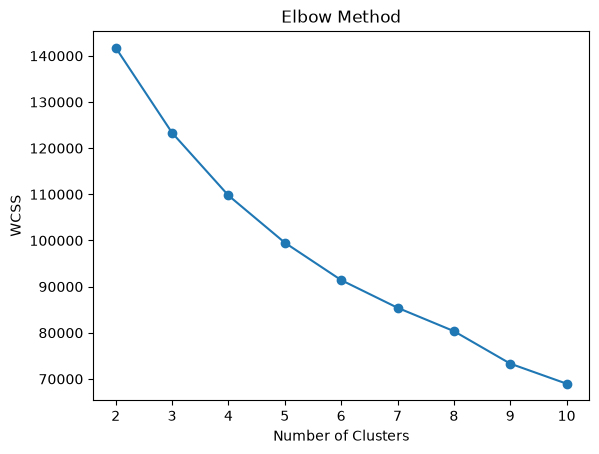

In [38]:
# ELBOW METHOD
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for i in range(2, 11):
    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(cluster_scaled)
    wcss.append(model.inertia_)

plt.plot(range(2, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [39]:
from sklearn.metrics import silhouette_score

for i in range(2, 9):
    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(cluster_scaled)

    score = silhouette_score(
        cluster_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    print("Clusters:", i, "| Silhouette Score:", round(score, 4))

Clusters: 2 | Silhouette Score: 0.9577
Clusters: 3 | Silhouette Score: 0.958
Clusters: 4 | Silhouette Score: 0.6417
Clusters: 5 | Silhouette Score: 0.2763
Clusters: 6 | Silhouette Score: 0.2839
Clusters: 7 | Silhouette Score: 0.2846
Clusters: 8 | Silhouette Score: 0.2917


In [40]:
for i in [2, 3]:
    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(cluster_scaled)

    print("\nNumber of clusters:", i)
    print(pd.Series(labels).value_counts().sort_index())


Number of clusters: 2
0    10002
1        4
Name: count, dtype: int64

Number of clusters: 3
0    10000
1        3
2        3
Name: count, dtype: int64


In [41]:
model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = model.fit_predict(cluster_scaled)

# Find the smaller cluster
small_cluster = pd.Series(labels).value_counts().idxmin()

# Get records belonging to that cluster
small_indices = pd.Series(labels)[
    pd.Series(labels) == small_cluster
].index

print("Number of isolated records:", len(small_indices))

print("\nTheir original water-quality values:")
print(cluster_data_clean.iloc[small_indices])

print("\nTheir station details:")
print(river_work.loc[small_indices, metadata_cols])

Number of isolated records: 4

Their original water-quality values:
      Temperature (°C) Min  Temperature (°C) Max  Dissolved Oxygen (mg/L) Min  \
6332                  19.0                  29.0                          0.0   
6333                  19.0                  29.0                          0.0   
6346                  19.0                  29.0                          0.0   
6844                  23.0                  31.0                          0.0   

      Dissolved Oxygen (mg/L) Max  pH Min  pH Max  Conductivity (µmho/cm) Min  \
6332                          5.4     7.2     8.5                       206.0   
6333                          3.9     7.2     8.5                       206.0   
6346                          5.1     7.1     8.6                       206.0   
6844                          6.8     7.6     8.4                      1337.0   

      Conductivity (µmho/cm) Max  BOD (mg/L) Min  BOD (mg/L) Max  \
6332                       457.0             4.0    

In [42]:
check_cols = metadata_cols + [
    "Dissolved Oxygen (mg/L) Min",
    "Fecal Coliform (MPN/100ml) Max",
    "Total Coliform (MPN/100ml) Max"
]

print(river_work.loc[small_indices, check_cols].to_string())

     Station Code                                                       Monitoring Location      State  Year Dissolved Oxygen (mg/L) Min Fecal Coliform (MPN/100ml) Max Total Coliform (MPN/100ml) Max
6332         1121                                                      YAMUNA AT NIZAMUDDIN      DELHI  2012                           0                    20000000000                    20000000000
6333         1375                              YAMUNA AT OKHLA BRIDGE (INLET OF AGRA CANAL)      DELHI  2012                           0                    20000000000                    20000000000
6346         1812                           YAMUNA AT OKHLA AFTER MEETING OF SHAHDARA DRAIN      DELHI  2012                           0                    20000000000                    20000000000
6844         3024  SARABANGA AT SALEM, D/S OF TEXTILE DYEING INDUSTRIES EFFLUENT, TAMILNADU  TAMILNADU  2014                           0                     3500000000                    16000000000


In [43]:
coliform_cols = [
    "Fecal Coliform (MPN/100ml) Min",
    "Fecal Coliform (MPN/100ml) Max",
    "Total Coliform (MPN/100ml) Min",
    "Total Coliform (MPN/100ml) Max"
]

print(cluster_data_clean[coliform_cols].describe())

       Fecal Coliform (MPN/100ml) Min  Fecal Coliform (MPN/100ml) Max  \
count                         10006.0                         10006.0   
mean                      3135.137228                  6605384.341445   
std                      30836.787323                348157028.470758   
min                               0.0                             0.0   
25%                               8.0                            63.0   
50%                              58.0                           470.0   
75%                             350.0                          2900.0   
max                         2200000.0                   20000000000.0   

       Total Coliform (MPN/100ml) Min  Total Coliform (MPN/100ml) Max  
count                         10006.0                         10006.0  
mean                      8514.643428                   8266820.54632  
std                     119907.904536                382261339.225308  
min                               0.0                 

In [44]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Create a separate dataset
cluster_log = cluster_data_clean.copy()

# Apply logarithmic transformation
for col in coliform_cols:
    cluster_log[col] = np.log1p(cluster_log[col])

# Scale the transformed dataset
scaler_log = StandardScaler()

cluster_scaled_log = pd.DataFrame(
    scaler_log.fit_transform(cluster_log),
    columns=cluster_features
)

print("Transformed dataset shape:", cluster_scaled_log.shape)
print("\nTransformed coliform statistics:")
print(cluster_log[coliform_cols].describe())

Transformed dataset shape: (10006, 16)

Transformed coliform statistics:
       Fecal Coliform (MPN/100ml) Min  Fecal Coliform (MPN/100ml) Max  \
count                         10006.0                         10006.0   
mean                         4.287468                         6.37934   
std                          2.519721                        3.174967   
min                               0.0                             0.0   
25%                          2.197225                        4.158883   
50%                          4.077537                        6.154858   
75%                          5.860786                        7.972811   
max                         14.603968                       23.718998   

       Total Coliform (MPN/100ml) Min  Total Coliform (MPN/100ml) Max  
count                         10006.0                         10006.0  
mean                         5.705793                        7.660354  
std                          2.257921                

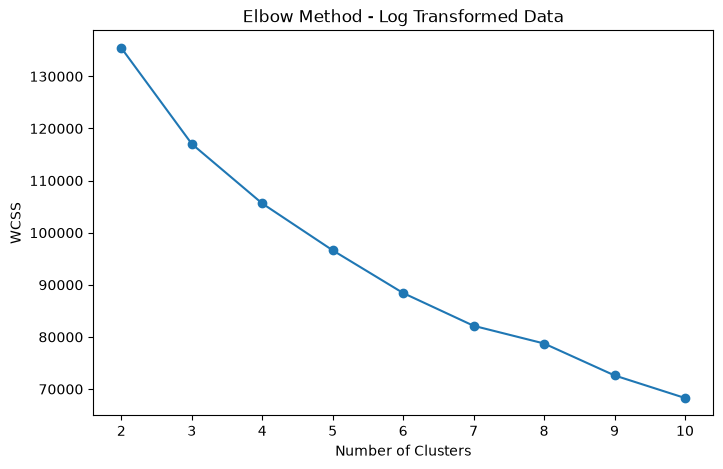

In [45]:
wcss_log = []

for i in range(2, 11):
    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(cluster_scaled_log)
    wcss_log.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), wcss_log, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method - Log Transformed Data")
plt.show()

In [46]:
from sklearn.metrics import silhouette_score

for i in range(2, 9):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(cluster_scaled_log)

    score = silhouette_score(
        cluster_scaled_log,
        labels,
        sample_size=2000,
        random_state=42
    )

    print("Clusters:", i, "| Silhouette Score:", round(score, 4))

Clusters: 2 | Silhouette Score: 0.2514
Clusters: 3 | Silhouette Score: 0.2493
Clusters: 4 | Silhouette Score: 0.2227
Clusters: 5 | Silhouette Score: 0.2137
Clusters: 6 | Silhouette Score: 0.2154
Clusters: 7 | Silhouette Score: 0.1941
Clusters: 8 | Silhouette Score: 0.1942


In [47]:
for i in [2, 3, 4]:

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(cluster_scaled_log)

    print("\nNumber of clusters:", i)
    print(pd.Series(labels).value_counts().sort_index())


Number of clusters: 2
0    6423
1    3583
Name: count, dtype: int64

Number of clusters: 3
0    6410
1    3593
2       3
Name: count, dtype: int64

Number of clusters: 4
0    5909
1    3674
2       4
3     419
Name: count, dtype: int64


In [48]:
final_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = final_model.fit_predict(cluster_scaled_log)

# Create final clustering results
cluster_results = cluster_data_clean.copy()

cluster_results["Cluster"] = cluster_labels

print("Cluster distribution:")
print(cluster_results["Cluster"].value_counts().sort_index())

Cluster distribution:
Cluster
0    6423
1    3583
Name: count, dtype: int64


In [49]:
cluster_profile = cluster_results.groupby("Cluster").median()

print(cluster_profile.T)

Cluster                             0        1
Temperature (°C) Min             19.0     19.0
Temperature (°C) Max             28.0     31.0
Dissolved Oxygen (mg/L) Min       6.4      5.4
Dissolved Oxygen (mg/L) Max       7.9      8.5
pH Min                            7.3      7.2
pH Max                            8.2      8.2
Conductivity (µmho/cm) Min      206.0    216.0
Conductivity (µmho/cm) Max      457.0    473.0
BOD (mg/L) Min                    1.3      1.9
BOD (mg/L) Max                    2.4      3.6
Nitrate N (mg/L) Min             0.32     0.32
Nitrate N (mg/L) Max              1.3      1.3
Fecal Coliform (MPN/100ml) Min   20.0    800.0
Fecal Coliform (MPN/100ml) Max  140.0  11000.0
Total Coliform (MPN/100ml) Min  110.0   2100.0
Total Coliform (MPN/100ml) Max  540.0  24000.0


In [50]:
cluster_percentages = (
    cluster_results["Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Cluster percentages:")
print(cluster_percentages.round(2))

Cluster percentages:
Cluster
0    64.19
1    35.81
Name: proportion, dtype: float64


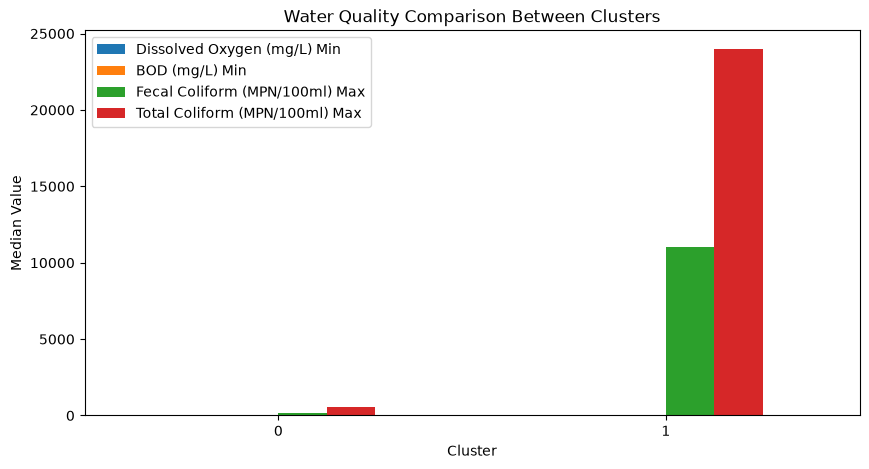

In [51]:
cluster_profile[
    [
        "Dissolved Oxygen (mg/L) Min",
        "BOD (mg/L) Min",
        "Fecal Coliform (MPN/100ml) Max",
        "Total Coliform (MPN/100ml) Max"
    ]
].plot(kind="bar", figsize=(10, 5))

plt.title("Water Quality Comparison Between Clusters")
plt.ylabel("Median Value")
plt.xticks(rotation=0)
plt.show()

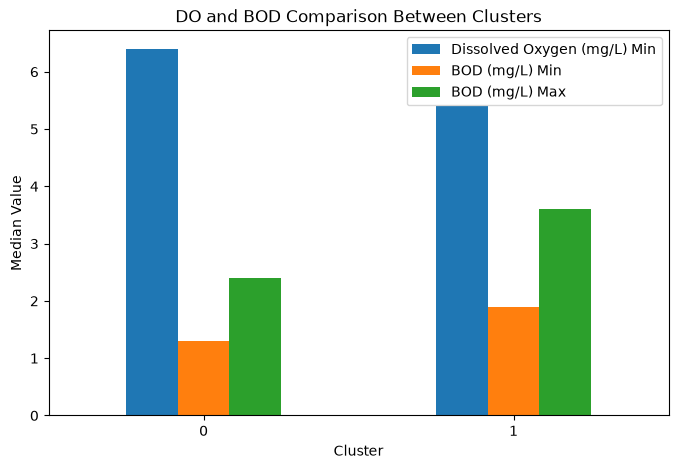

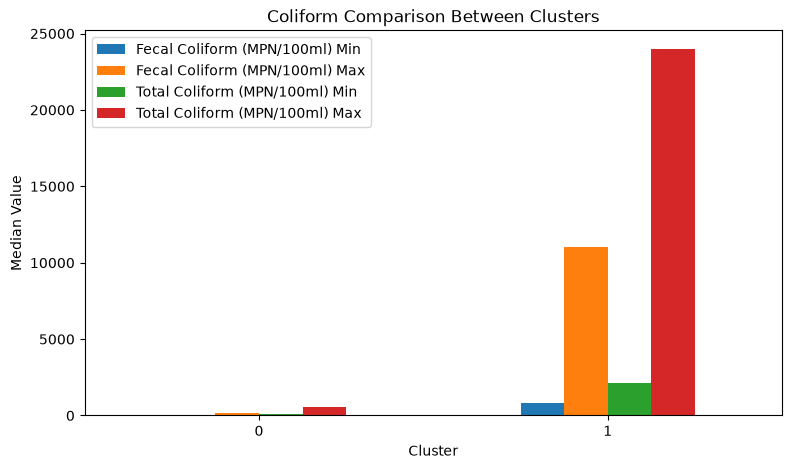

In [52]:
cluster_profile[
    [
        "Dissolved Oxygen (mg/L) Min",
        "BOD (mg/L) Min",
        "BOD (mg/L) Max"
    ]
].plot(kind="bar", figsize=(8, 5))

plt.title("DO and BOD Comparison Between Clusters")
plt.ylabel("Median Value")
plt.xlabel("Cluster")
plt.xticks(rotation=0)
plt.show()


cluster_profile[
    [
        "Fecal Coliform (MPN/100ml) Min",
        "Fecal Coliform (MPN/100ml) Max",
        "Total Coliform (MPN/100ml) Min",
        "Total Coliform (MPN/100ml) Max"
    ]
].plot(kind="bar", figsize=(9, 5))

plt.title("Coliform Comparison Between Clusters")
plt.ylabel("Median Value")
plt.xlabel("Cluster")
plt.xticks(rotation=0)
plt.show()

In [53]:
cluster_output = river_work[metadata_cols].copy()

cluster_output["Cluster"] = cluster_results["Cluster"]

print(cluster_output.head())
print("\nTotal records:", len(cluster_output))

  Station Code                                Monitoring Location  \
0         1001                           RIVER BEAS AT U/S MANALI   
1         2601                           RIVER BEAS AT D/S MANALI   
2         4444  RIVER BEAS D/S OF WASTE PROCESSING FACILITY AT...   
3         4037                      RIVER BEAS D/S MANALSU NALLAH   
4         3866      RIVER BEAS U/S BEFORE CONF. OF MANALSU NALLAH   

              State  Year  Cluster  
0  HIMACHAL PRADESH  2023        0  
1  HIMACHAL PRADESH  2023        0  
2  HIMACHAL PRADESH  2023        0  
3  HIMACHAL PRADESH  2023        0  
4  HIMACHAL PRADESH  2023        0  

Total records: 10006


In [54]:
from sklearn.ensemble import IsolationForest

anomaly_model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

anomaly_labels = anomaly_model.fit_predict(cluster_scaled_log)

print("Anomaly detection completed!")

print("\nNormal records:", (anomaly_labels == 1).sum())
print("Anomalous records:", (anomaly_labels == -1).sum())

Anomaly detection completed!

Normal records: 9555
Anomalous records: 451


In [55]:
anomaly_results = river_work[metadata_cols].copy()

anomaly_results["Anomaly"] = anomaly_labels

anomaly_results["Status"] = anomaly_results["Anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

print(anomaly_results.head())

print("\nAnomaly distribution:")
print(anomaly_results["Status"].value_counts())

  Station Code                                Monitoring Location  \
0         1001                           RIVER BEAS AT U/S MANALI   
1         2601                           RIVER BEAS AT D/S MANALI   
2         4444  RIVER BEAS D/S OF WASTE PROCESSING FACILITY AT...   
3         4037                      RIVER BEAS D/S MANALSU NALLAH   
4         3866      RIVER BEAS U/S BEFORE CONF. OF MANALSU NALLAH   

              State  Year  Anomaly  Status  
0  HIMACHAL PRADESH  2023        1  Normal  
1  HIMACHAL PRADESH  2023        1  Normal  
2  HIMACHAL PRADESH  2023        1  Normal  
3  HIMACHAL PRADESH  2023        1  Normal  
4  HIMACHAL PRADESH  2023        1  Normal  

Anomaly distribution:
Status
Normal     9555
Anomaly     451
Name: count, dtype: int64


In [56]:
# Calculate anomaly scores
anomaly_scores = anomaly_model.decision_function(cluster_scaled_log)

# Add scores to our results
anomaly_results["Anomaly Score"] = anomaly_scores

# Select anomalous observations
anomaly_records = anomaly_results[
    anomaly_results["Anomaly"] == -1
]

# Display the 10 most unusual records
print(
    anomaly_records.sort_values("Anomaly Score").head(10).to_string(index=False)
)

Station Code                                                 Monitoring Location         State  Year  Anomaly  Status  Anomaly Score
        1358                                       HINDON AT GHAZIABAD D/S, U.P. UTTAR PRADESH  2018       -1 Anomaly      -0.217782
        2483                     RIVER VARUNA B-C WITH RIVER GANGA AT\n VARANASI UTTAR PRADESH  2018       -1 Anomaly      -0.207355
        1357                                      HINDON AT SAHARANPUR D-S, U.P. UTTAR PRADESH  2018       -1 Anomaly      -0.195581
        2497       KALI EAST AT KHARKHODA-PARIKSHIT GARH ROAD, VILL. KOL, MEERUT UTTAR PRADESH  2012       -1 Anomaly      -0.193428
        2496      RIVER HINDON AT SARDHANA BUDHANA ROAD, VILLAGE BAPARSI, MEERUT UTTAR PRADESH  2019       -1 Anomaly      -0.193157
        2496      RIVER HINDON AT SARDHANA BUDHANA ROAD, VILLAGE BAPARSI, MEERUT UTTAR PRADESH  2020       -1 Anomaly      -0.193157
        2497 RIVER KALI EAST AT KHARKHODA-PARIKSHIT GARH ROAD, VILL. 

In [57]:
# Select the 10 most unusual observations
top_anomalies = anomaly_records.sort_values(
    "Anomaly Score"
).head(10)

# Get their original water-quality measurements
top_measurements = cluster_data_clean.loc[top_anomalies.index]

# Display measurements with station details
top_anomaly_details = pd.concat(
    [
        top_anomalies[metadata_cols + ["Anomaly Score"]],
        top_measurements
    ],
    axis=1
)

print(top_anomaly_details.to_string())

     Station Code                                                  Monitoring Location          State  Year  Anomaly Score  Temperature (°C) Min  Temperature (°C) Max  Dissolved Oxygen (mg/L) Min  Dissolved Oxygen (mg/L) Max  pH Min  pH Max  Conductivity (µmho/cm) Min  Conductivity (µmho/cm) Max  BOD (mg/L) Min  BOD (mg/L) Max  Nitrate N (mg/L) Min  Nitrate N (mg/L) Max  Fecal Coliform (MPN/100ml) Min  Fecal Coliform (MPN/100ml) Max  Total Coliform (MPN/100ml) Min  Total Coliform (MPN/100ml) Max
5456         1358                                        HINDON AT GHAZIABAD D/S, U.P.  UTTAR PRADESH  2018      -0.217782                  18.0                  42.0                          0.0                          0.0     7.8   809.0                        40.5                        84.0            0.54            64.0              130000.0              190000.0                        280000.0                        310000.0                           267.5                          1600.

In [58]:
ph_issues = river_numeric[
    (river_numeric["pH Min"] > 14) |
    (river_numeric["pH Max"] > 14)
]

print("Suspicious pH records:", len(ph_issues))

print(
    river_work.loc[
        ph_issues.index,
        metadata_cols + ["pH Min", "pH Max"]
    ].to_string()
)

Suspicious pH records: 30
     Station Code                                                         Monitoring Location          State  Year pH Min pH Max
5448         2730                                     PILKHAR RIVER\n AFTER BILASPUR\n RAMPUR    UTTARAKHAND  2018    7.2    220
5449         2736                       NANDAUR RIVER U/S SITARGANJ INDUSTRIAL AREA, US NAGAR    UTTARAKHAND  2018    7.3    270
5450         2737                       NANDAUR RIVER D-S SITARGANJ INDUSTRIAL AREA, US NAGAR    UTTARAKHAND  2018    7.1    350
5451         1064                                     RAMGANGA AT KANNAUJ (BEFORE CONF.), U.P  UTTAR PRADESH  2018      9    235
5452         2497                        RIVER KALI EAST AT KHARKHODA- PARIKSHIT GARH\n ROAD,  UTTAR PRADESH  2018    7.7   1480
5453         1065                                     KALINADI AT KANNAUJ (BEFORE CONF.), U.P  UTTAR PRADESH  2018    8.9    214
5454         2496                        RIVER HINDON AT\n SARDHANA BUD

In [59]:
ph_issues = river_numeric[
    (river_numeric["pH Min"] > 14) |
    (river_numeric["pH Max"] > 14)
].copy()

ph_issues["Issue"] = "Suspicious pH value above 14"

print("Total suspicious pH records:", len(ph_issues))

Total suspicious pH records: 30


In [60]:
ph_anomaly_overlap = ph_issues.index.intersection(
    anomaly_records.index
)

print("Suspicious pH records also detected as anomalies:",
      len(ph_anomaly_overlap))

Suspicious pH records also detected as anomalies: 24


In [61]:
ph_not_detected = ph_issues.index.difference(
    anomaly_records.index
)

print("Suspicious pH records not detected:", len(ph_not_detected))

print(river_work.loc[
    ph_not_detected,
    metadata_cols + ["pH Min", "pH Max"]
].to_string())

Suspicious pH records not detected: 6
     Station Code                                    Monitoring Location          State  Year pH Min pH Max
5448         2730                PILKHAR RIVER\n AFTER BILASPUR\n RAMPUR    UTTARAKHAND  2018    7.2    220
5449         2736  NANDAUR RIVER U/S SITARGANJ INDUSTRIAL AREA, US NAGAR    UTTARAKHAND  2018    7.3    270
5450         2737  NANDAUR RIVER D-S SITARGANJ INDUSTRIAL AREA, US NAGAR    UTTARAKHAND  2018    7.1    350
6584         1361                 SAI AT UNNAO AFTER DRAIN OUTFALL, U.P.  UTTAR PRADESH  2014    7.1     71
6899         1091           BHADRA AT MALLESWARAM D/S OF KIOCL KARNATAKA      KARNATAKA  2014    7.2     75
6928         1184            BHIMA AT FEROZABAD VILLAGE (D/S), KARNATAKA      KARNATAKA  2014      8     84


In [62]:
quality_issue_indexes = set(min_max_issues.index)

quality_issue_indexes.update(ph_issues.index)

quality_issue_indexes.add(3701)

print("Unique records with identified data-quality issues:",
      len(quality_issue_indexes))

Unique records with identified data-quality issues: 87


In [63]:
quality_anomaly_overlap = quality_issue_indexes.intersection(
    anomaly_records.index
)

print("Data-quality records:", len(quality_issue_indexes))
print("Also detected by Isolation Forest:",
      len(quality_anomaly_overlap))
print("Not detected by Isolation Forest:",
      len(quality_issue_indexes) - len(quality_anomaly_overlap))

Data-quality records: 87
Also detected by Isolation Forest: 24
Not detected by Isolation Forest: 63


In [64]:
statistical_anomaly_indexes = anomaly_records.index.difference(
    quality_issue_indexes
)

print("Statistical anomalies without identified data-quality issues:",
      len(statistical_anomaly_indexes))

Statistical anomalies without identified data-quality issues: 427


In [65]:
statistical_anomalies = anomaly_results.loc[
    statistical_anomaly_indexes
].sort_values("Anomaly Score")

print(
    statistical_anomalies.head(10).to_string()
)

     Station Code                                                  Monitoring Location          State  Year  Anomaly   Status  Anomaly Score
6356         2497        KALI EAST AT KHARKHODA-PARIKSHIT GARH ROAD, VILL. KOL, MEERUT  UTTAR PRADESH  2012       -1  Anomaly      -0.193428
9135         2496       RIVER HINDON AT SARDHANA BUDHANA ROAD, VILLAGE BAPARSI, MEERUT  UTTAR PRADESH  2019       -1  Anomaly      -0.193157
7963         2496       RIVER HINDON AT SARDHANA BUDHANA ROAD, VILLAGE BAPARSI, MEERUT  UTTAR PRADESH  2020       -1  Anomaly      -0.193157
8178         2497  RIVER KALI EAST AT KHARKHODA-PARIKSHIT GARH ROAD, VILL. KOL, MEERUT  UTTAR PRADESH  2020       -1  Anomaly      -0.188605
8015         2497  RIVER KALI EAST AT KHARKHODA-PARIKSHIT GARH ROAD, VILL. KOL, MEERUT  UTTAR PRADESH  2020       -1  Anomaly      -0.188605
9187         2497  RIVER KALI EAST AT KHARKHODA-PARIKSHIT GARH ROAD, VILL. KOL, MEERUT  UTTAR PRADESH  2019       -1  Anomaly      -0.188605
9350         

In [66]:
top10_indexes = statistical_anomalies.head(10).index

top10_details = river_work.loc[
    top10_indexes,
    metadata_cols + cluster_features
]

print(top10_details.to_string())

     Station Code                                                  Monitoring Location          State  Year Temperature (°C) Min Temperature (°C) Max Dissolved Oxygen (mg/L) Min Dissolved Oxygen (mg/L) Max pH Min pH Max Conductivity (µmho/cm) Min Conductivity (µmho/cm) Max BOD (mg/L) Min BOD (mg/L) Max Nitrate N (mg/L) Min Nitrate N (mg/L) Max Fecal Coliform (MPN/100ml) Min Fecal Coliform (MPN/100ml) Max Total Coliform (MPN/100ml) Min Total Coliform (MPN/100ml) Max
6356         2497        KALI EAST AT KHARKHODA-PARIKSHIT GARH ROAD, VILL. KOL, MEERUT  UTTAR PRADESH  2012                   11                   37                         NaN                         NaN    7.3    7.9                       1470                       1942             74             94                  8.1                  9.8                         300000                         300000                         400000                         400000
9135         2496       RIVER HINDON AT SARDHANA BUDHANA ROA

In [67]:
anomaly_measurements = river_work.loc[
    statistical_anomaly_indexes,
    cluster_features
]

duplicate_profiles = anomaly_measurements.duplicated(keep=False)

print("Records with repeated measurement profiles:",
      duplicate_profiles.sum())

print("Unique repeated profiles:",
      anomaly_measurements[duplicate_profiles].drop_duplicates().shape[0])

Records with repeated measurement profiles: 94
Unique repeated profiles: 35


In [68]:
combined_results = river_work[metadata_cols].copy()

combined_results["Cluster"] = cluster_results["Cluster"]

combined_results["Anomaly Status"] = anomaly_results["Status"]

combined_results["Anomaly Score"] = anomaly_results["Anomaly Score"]

combined_results["Data Quality Issue"] = (
    combined_results.index.isin(quality_issue_indexes)
)

print("Combined dataset shape:", combined_results.shape)

print(combined_results.head())

Combined dataset shape: (10006, 8)
  Station Code                                Monitoring Location  \
0         1001                           RIVER BEAS AT U/S MANALI   
1         2601                           RIVER BEAS AT D/S MANALI   
2         4444  RIVER BEAS D/S OF WASTE PROCESSING FACILITY AT...   
3         4037                      RIVER BEAS D/S MANALSU NALLAH   
4         3866      RIVER BEAS U/S BEFORE CONF. OF MANALSU NALLAH   

              State  Year  Cluster Anomaly Status  Anomaly Score  \
0  HIMACHAL PRADESH  2023        0         Normal       0.126334   
1  HIMACHAL PRADESH  2023        0         Normal       0.104042   
2  HIMACHAL PRADESH  2023        0         Normal       0.107468   
3  HIMACHAL PRADESH  2023        0         Normal       0.095874   
4  HIMACHAL PRADESH  2023        0         Normal       0.108268   

   Data Quality Issue  
0                True  
1                True  
2                True  
3                True  
4                True

In [69]:
quality_issue_indexes = set(
    min_max_issues["Original Index"]
)

quality_issue_indexes.update(ph_issues.index)

quality_issue_indexes.add(3701)

combined_results["Data Quality Issue"] = (
    combined_results.index.isin(quality_issue_indexes)
)

print("Unique data-quality records:", len(quality_issue_indexes))

print(combined_results["Data Quality Issue"].value_counts())

print(combined_results.head())

Unique data-quality records: 87
Data Quality Issue
False    9919
True       87
Name: count, dtype: int64
  Station Code                                Monitoring Location  \
0         1001                           RIVER BEAS AT U/S MANALI   
1         2601                           RIVER BEAS AT D/S MANALI   
2         4444  RIVER BEAS D/S OF WASTE PROCESSING FACILITY AT...   
3         4037                      RIVER BEAS D/S MANALSU NALLAH   
4         3866      RIVER BEAS U/S BEFORE CONF. OF MANALSU NALLAH   

              State  Year  Cluster Anomaly Status  Anomaly Score  \
0  HIMACHAL PRADESH  2023        0         Normal       0.126334   
1  HIMACHAL PRADESH  2023        0         Normal       0.104042   
2  HIMACHAL PRADESH  2023        0         Normal       0.107468   
3  HIMACHAL PRADESH  2023        0         Normal       0.095874   
4  HIMACHAL PRADESH  2023        0         Normal       0.108268   

   Data Quality Issue  
0               False  
1               False  

In [70]:
print("Total records:", len(combined_results))

print("\nCluster distribution:")
print(combined_results["Cluster"].value_counts())

print("\nAnomaly distribution:")
print(combined_results["Anomaly Status"].value_counts())

print("\nData-quality distribution:")
print(combined_results["Data Quality Issue"].value_counts())

combined_results.to_csv(
    "aquavista_combined_results.csv",
    index=False
)

print("\nCombined results saved successfully!")

Total records: 10006

Cluster distribution:
Cluster
0    6423
1    3583
Name: count, dtype: int64

Anomaly distribution:
Anomaly Status
Normal     9555
Anomaly     451
Name: count, dtype: int64

Data-quality distribution:
Data Quality Issue
False    9919
True       87
Name: count, dtype: int64

Combined results saved successfully!
